# VISIONPORT - Traffic Monitoring

In [ ]:
# ================================================================
# TASK 1: Install Python, OpenCV and required libraries
# Expected output: Working Python environment
# ================================================================

!pip install -q ultralytics opencv-python matplotlib pandas==2.2.3

import os
import math
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter, defaultdict
from ultralytics import YOLO
from google.colab import files
from IPython.display import display, Video

print("VISIONPORT INITIALIZING...")

# ---- Environment check ----
print("\nSYSTEM INFORMATION")
print("OpenCV:", cv2.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = 0
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    print("GPU: Not available. Using CPU instead.")

# ---- Configuration (used by the later tasks) ----
# Adjust these according to your video.
CONFIDENCE = 0.25
IMAGE_SIZE = 960

# Task 13 - speed: set after calibrating the camera (e.g. 20 pixels = 1 meter).
PIXELS_PER_METER = None

# Task 16 - entry / exit lines (fraction of the frame height).
ENTRY_LINE_RATIO = 0.25
EXIT_LINE_RATIO = 0.75

# Task 18 - expected traffic direction: "down" or "up".
EXPECTED_DIRECTION = "down"

# Task 19 - restricted parking zone as polygon points in percent of the frame.
# Example: [(10, 60), (40, 60), (40, 90), (10, 90)]. Empty list = not configured.
RESTRICTED_ZONE = []
PARKING_THRESHOLD = 10          # seconds

# Tasks 10-11 - traffic density thresholds (vehicles per frame).
LOW_TRAFFIC = 5
HIGH_TRAFFIC = 15

# Output folders
FRAMES_DIR = "/content/VISIONPORT_Frames"
RESULTS_DIR = "/content/VISIONPORT_Results"
os.makedirs(FRAMES_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("\nTask 1 complete: environment ready.")

VISIONPORT INITIALIZING...

SYSTEM INFORMATION
OpenCV: 5.0.0
PyTorch: 2.14.1+cpu
CUDA: False
GPU: Not available. Using CPU instead.

Task 1 complete: environment ready.


In [ ]:
# ================================================================
# TASK 2: Capture an image of a traffic signal using a camera
# Expected output: Traffic image capture
# ================================================================
# Take a photo of a traffic signal with your camera / phone and upload it here.

print("UPLOAD A TRAFFIC SIGNAL IMAGE")

uploaded_image = files.upload()

if not uploaded_image:
    raise ValueError("Please upload a traffic image.")

image_path = next(iter(uploaded_image))

print("Image captured:", image_path)

UPLOAD A TRAFFIC SIGNAL IMAGE


Saving yes.webp to yes.webp
Image captured: yes.webp


Image: yes.webp
Resolution: 480 x 270


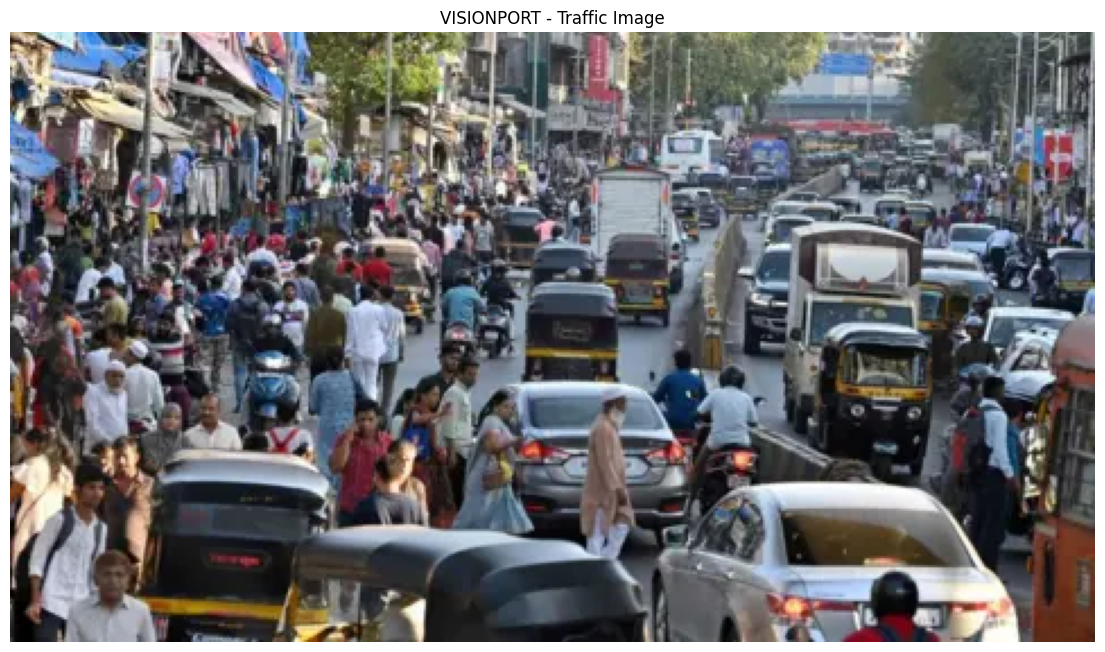

In [ ]:
# ================================================================
# TASK 3: Read and display traffic images using OpenCV
# Expected output: Image display window
# ================================================================

image = cv2.imread(image_path)

if image is None:
    raise ValueError("Invalid image.")

height, width = image.shape[:2]

print("Image:", image_path)
print("Resolution:", width, "x", height)

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("VISIONPORT - Traffic Image")
plt.axis("off")
plt.show()

In [ ]:
# ================================================================
# TASK 4: Load and play a traffic video using OpenCV
# Expected output: Video playback
# ================================================================

print("UPLOAD A TRAFFIC VIDEO (used for Tasks 4-20)")

uploaded_video = files.upload()

if not uploaded_video:
    raise ValueError("Please upload a traffic video.")

video_path = next(iter(uploaded_video))

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError("Unable to open video.")

fps = cap.get(cv2.CAP_PROP_FPS)

if not np.isfinite(fps) or fps <= 0:
    fps = 25.0

video_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
video_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

cap.release()

print("\nVIDEO INFORMATION")
print("Width:", video_width)
print("Height:", video_height)
print("FPS:", fps)
print("Total Frames:", total_frames)
print("Duration:", round(total_frames / fps, 2), "seconds")


# ---- Helpers reused by the later tasks ----
def read_frames(path):
    """Yield (frame_number, frame) for every frame; numbering starts at 1."""
    reader = cv2.VideoCapture(path)
    n = 0
    while True:
        ret, frame = reader.read()
        if not ret:
            break
        n += 1
        yield n, frame
    reader.release()


def get_frame(path, n):
    """Return frame number n (1-based) or None."""
    reader = cv2.VideoCapture(path)
    reader.set(cv2.CAP_PROP_POS_FRAMES, n - 1)
    ret, frame = reader.read()
    reader.release()
    return frame if ret else None


# ---- Play the video ----
display(Video(video_path, embed=True, width=640))

UPLOAD A TRAFFIC VIDEO (used for Tasks 4-20)


Saving traffic.mp4 to traffic (1).mp4

VIDEO INFORMATION
Width: 640
Height: 360
FPS: 25.0
Total Frames: 5129
Duration: 205.16 seconds


Frames Extracted: 10
Saved in: /content/VISIONPORT_Frames


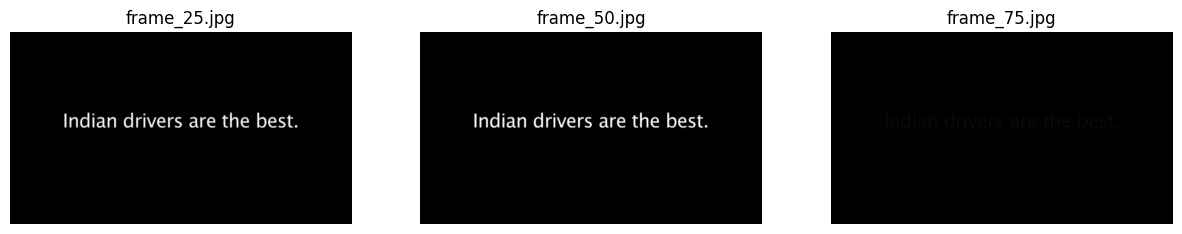

In [ ]:
# ================================================================
# TASK 5: Extract individual frames from traffic videos
# Expected output: Frames saved as images
# ================================================================
# Saves one frame per second for the first 10 seconds.

step = max(1, int(fps))
saved_frames = []

for n, frame in read_frames(video_path):

    if n > fps * 10:
        break

    if n % step == 0:
        file_name = os.path.join(FRAMES_DIR, f"frame_{n}.jpg")
        cv2.imwrite(file_name, frame)
        saved_frames.append(file_name)

print("Frames Extracted:", len(saved_frames))
print("Saved in:", FRAMES_DIR)

# Preview up to 3 extracted frames
if saved_frames:
    preview = saved_frames[:3]
    plt.figure(figsize=(15, 5))
    for i, file_name in enumerate(preview):
        plt.subplot(1, len(preview), i + 1)
        plt.imshow(cv2.cvtColor(cv2.imread(file_name), cv2.COLOR_BGR2RGB))
        plt.title(os.path.basename(file_name))
        plt.axis("off")
    plt.show()


Loading YOLO11 Nano...
Model Loaded Successfully!

IMAGE DETECTION REPORT
car : 15
person : 15
bus : 2
truck : 3
Total Objects: 35


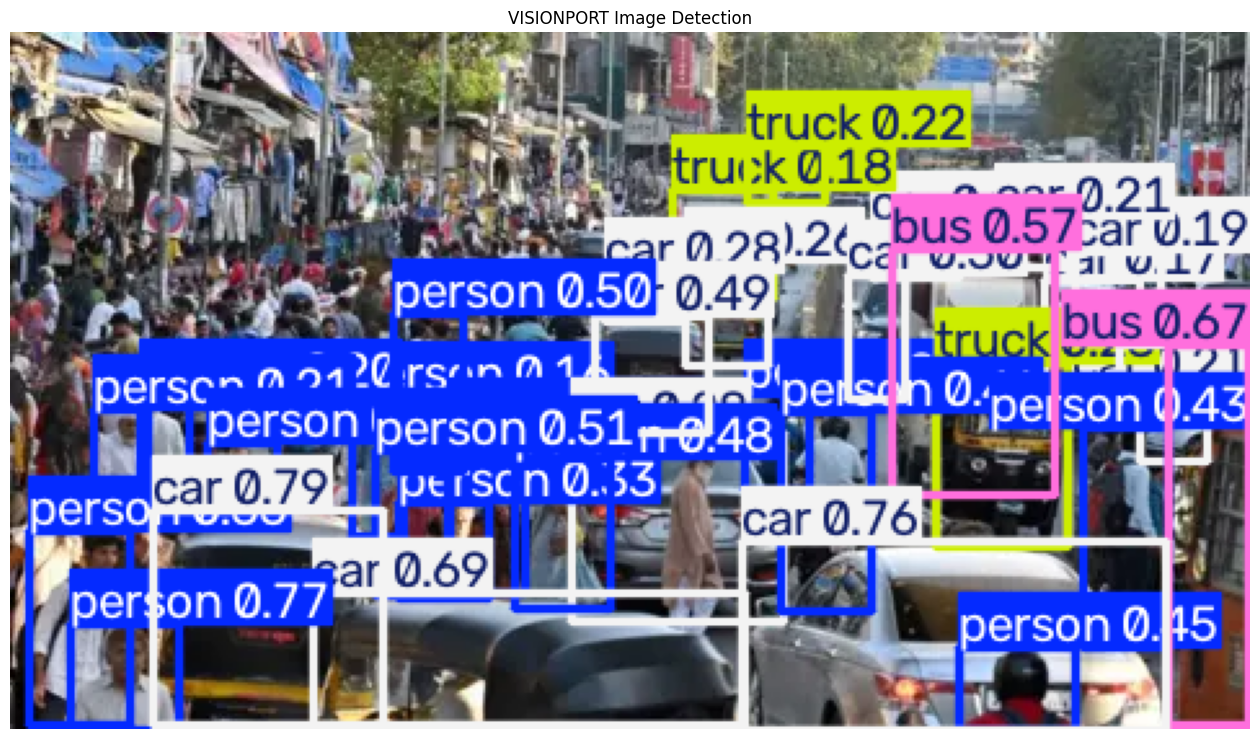


VISIONPORT VIDEO ANALYSIS STARTED
Processed 100 frames
Processed 200 frames
Processed 300 frames
Processed 400 frames
Processed 500 frames
Processed 600 frames
Processed 700 frames
Processed 800 frames
Processed 900 frames
Processed 1000 frames

VIDEO ANALYSIS COMPLETED!

CAR DETECTION REPORT
Frames processed: 1000
Total car detections: 4651
Max cars in one frame: 17


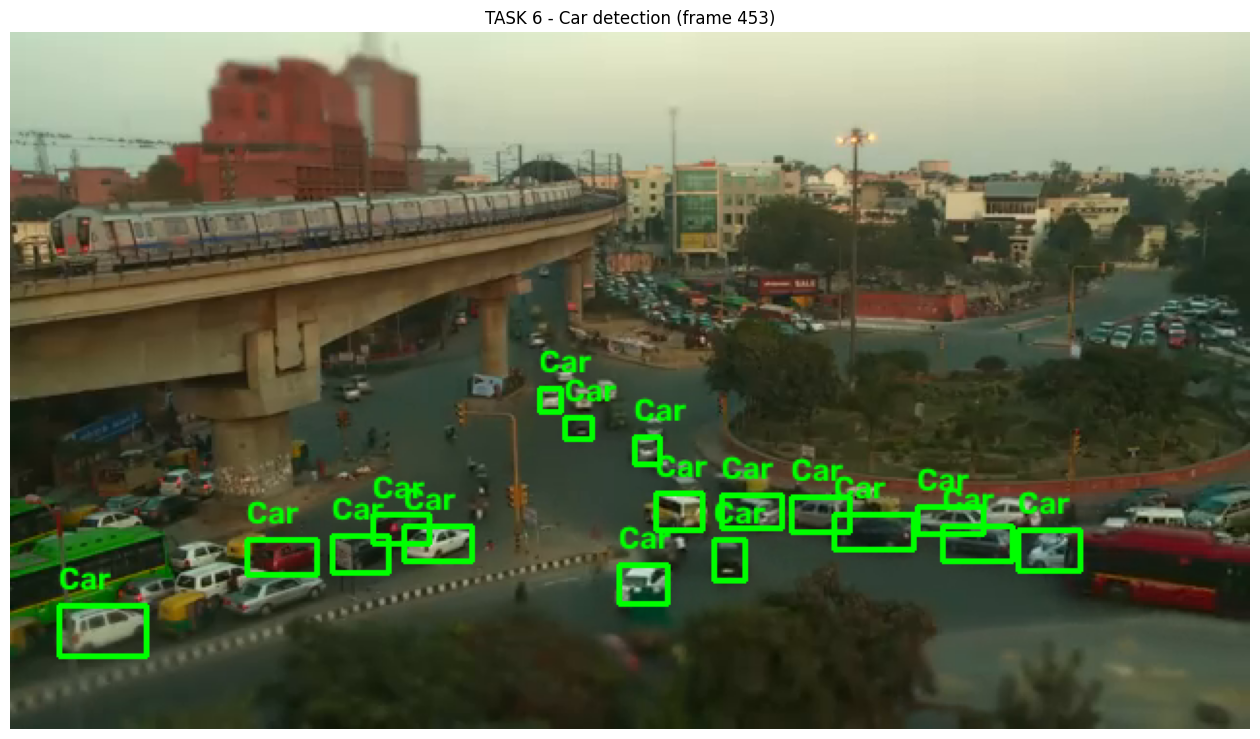

In [ ]:
# ================================================================
# TASK 6: Detect cars in a traffic video using YOLO
# Expected output: Car detection with bounding boxes
# ================================================================

print("\nLoading YOLO11 Nano...")

model = YOLO("yolo11n.pt")

print("Model Loaded Successfully!")

# COCO classes
PERSON = 0
BICYCLE = 1
CAR = 2
MOTORCYCLE = 3
BUS = 5
TRAIN = 6
TRUCK = 7
TRAFFIC_LIGHT = 9

VEHICLE_CLASSES = [BICYCLE, CAR, MOTORCYCLE, BUS, TRAIN, TRUCK]

VEHICLE_NAMES = {
    BICYCLE: "Bicycle",
    CAR: "Car",
    MOTORCYCLE: "Motorcycle",
    BUS: "Bus",
    TRAIN: "Train",
    TRUCK: "Truck"
}


def get_center(box):
    x1, y1, x2, y2 = box
    return (int((x1 + x2) / 2), int((y1 + y2) / 2))


def draw_detections(frame, dets, class_ids, show_conf=False, show_id=False):
    """Draw boxes + names for the detections whose class is in class_ids."""
    out = frame.copy()
    for d in dets:
        if d["cls"] not in class_ids:
            continue
        x1, y1, x2, y2 = d["box"]
        label = VEHICLE_NAMES.get(d["cls"], d["name"])
        if show_id and d["id"] is not None:
            label += f" ID:{d['id']}"
        if show_conf:
            label += f" {d['conf']:.2f}"
        cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(out, label, (x1, max(20, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 0), 2)
    return out


def show_frame(img, title):
    plt.figure(figsize=(16, 10))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


# ---- Detection on the still image from Task 2 ----
image_result = model.predict(
    source=image,
    imgsz=640,
    conf=0.15, # Lowered threshold for maximum recall
    device=DEVICE,
    max_det=1000,
    verbose=False
)[0]

print("\nIMAGE DETECTION REPORT")
for name, count in Counter(
    model.names[int(box.cls[0])] for box in image_result.boxes
).items():
    print(name, ":", count)
print("Total Objects:", len(image_result.boxes))

show_frame(image_result.plot(), "VISIONPORT Image Detection")

# ---- Detection + tracking on the whole video (Optimized) ----
print("\nVISIONPORT VIDEO ANALYSIS STARTED")

frame_data = []     # one entry per frame: {"frame", "time", "dets": [...]}

# Disable frame skipping to track vehicles continuously across every frame
skip_step = 1
last_dets = []

for n, frame in read_frames(video_path):
    if n > 1000:
        break

    if n % skip_step == 1 or skip_step == 1:
        result = model.track(
            source=frame,
            persist=True,
            tracker="bytetrack.yaml",
            imgsz=640,
            conf=0.15,  # Lowered confidence threshold for maximum sensitivity
            classes=[PERSON] + VEHICLE_CLASSES + [TRAFFIC_LIGHT],
            device=DEVICE,
            max_det=100,
            verbose=False
        )[0]

        dets = []
        if result.boxes is not None and len(result.boxes) > 0:
            for box in result.boxes:
                class_id = int(box.cls[0])
                x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
                dets.append({
                    "cls": class_id,
                    "name": model.names[class_id],
                    "conf": float(box.conf[0]),
                    "box": (x1, y1, x2, y2),
                    "center": get_center((x1, y1, x2, y2)),
                    "id": int(box.id[0]) if box.id is not None else None
                })
        last_dets = dets
    else:
        dets = last_dets

    frame_data.append({"frame": n, "time": n / fps, "dets": dets})

    if n % 100 == 0:
        print(f"Processed {n} frames")

print("\nVIDEO ANALYSIS COMPLETED!")

# ---- Task 6 output: cars ----
cars_per_frame = [
    sum(1 for d in f["dets"] if d["cls"] == CAR) for f in frame_data
]

print("\nCAR DETECTION REPORT")
print("Frames processed:", len(frame_data))
print("Total car detections:", sum(cars_per_frame))
print("Max cars in one frame:", max(cars_per_frame, default=0))

best_n = int(np.argmax(cars_per_frame)) + 1
sample = get_frame(video_path, best_n)

if sample is not None:
    show_frame(
        draw_detections(sample, frame_data[best_n - 1]["dets"], [CAR]),
        f"TASK 6 - Car detection (frame {best_n})"
    )

BIKE / BUS / TRUCK DETECTION REPORT
Bicycle : 0 detections
Motorcycle : 0 detections
Bus : 160 detections
Truck : 120 detections


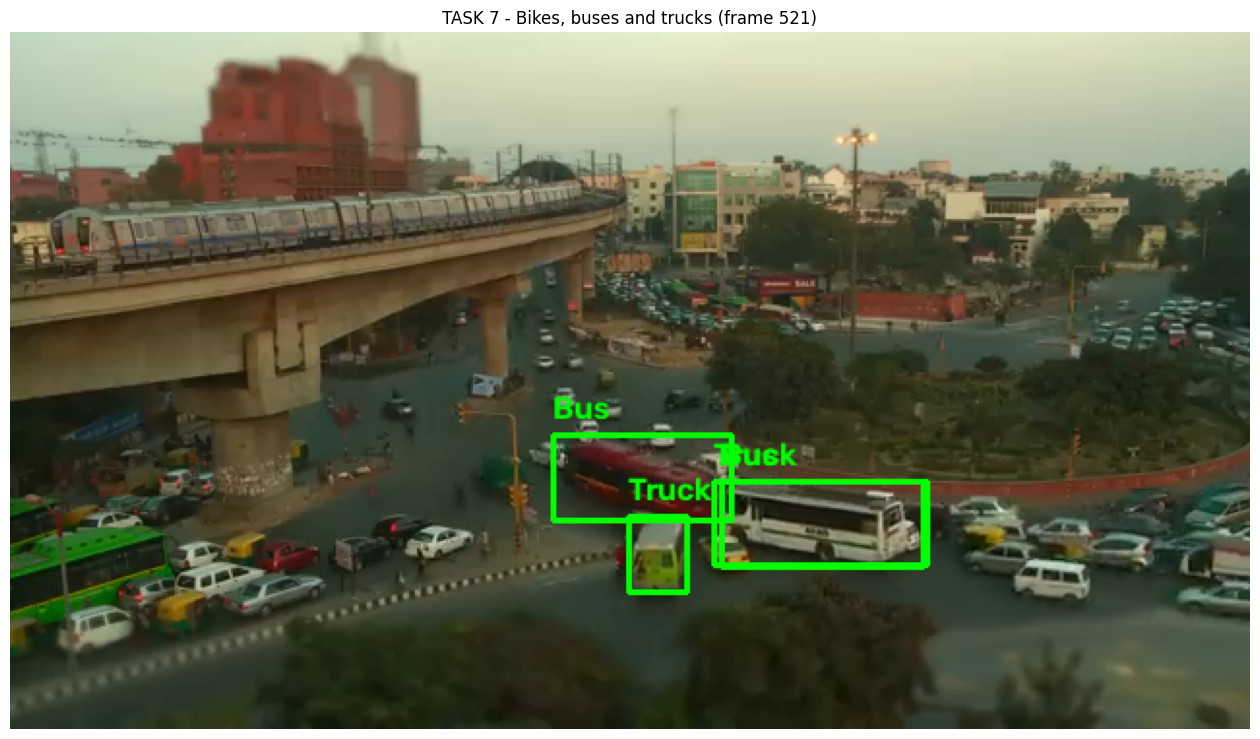

In [ ]:
# ================================================================
# TASK 7: Detect bikes, buses and trucks
# Expected output: Multiple vehicle detection
# ================================================================

BIKE_BUS_TRUCK = [BICYCLE, MOTORCYCLE, BUS, TRUCK]

detections_per_class = Counter(
    VEHICLE_NAMES[d["cls"]]
    for f in frame_data
    for d in f["dets"]
    if d["cls"] in BIKE_BUS_TRUCK
)

print("BIKE / BUS / TRUCK DETECTION REPORT")
for name in ["Bicycle", "Motorcycle", "Bus", "Truck"]:
    print(name, ":", detections_per_class.get(name, 0), "detections")

counts_per_frame = [
    sum(1 for d in f["dets"] if d["cls"] in BIKE_BUS_TRUCK) for f in frame_data
]

best_n = int(np.argmax(counts_per_frame)) + 1
sample = get_frame(video_path, best_n)

if sample is not None:
    show_frame(
        draw_detections(sample, frame_data[best_n - 1]["dets"], BIKE_BUS_TRUCK),
        f"TASK 7 - Bikes, buses and trucks (frame {best_n})"
    )

LABELLED DETECTIONS (frame 522)
Truck       ID:1027  confidence: 0.65
Car         ID:6     confidence: 0.62
Car         ID:877   confidence: 0.62
Car         ID:1201  confidence: 0.59
Train       ID:298   confidence: 0.58
Car         ID:1008  confidence: 0.45
Car         ID:1224  confidence: 0.45
Truck       ID:1145  confidence: 0.40
Car         ID:702   confidence: 0.36
Car         ID:1233  confidence: 0.31
Truck       ID:1240  confidence: 0.31
Bus         ID:940   confidence: 0.29
Car         ID:37    confidence: 0.29
Car         ID:1234  confidence: 0.29
Car         ID:608   confidence: 0.27
Car         ID:1219  confidence: 0.23
Car         ID:1232  confidence: 0.22
Car         ID:694   confidence: 0.19
Car         ID:1163  confidence: 0.19
Car         ID:1173  confidence: 0.19


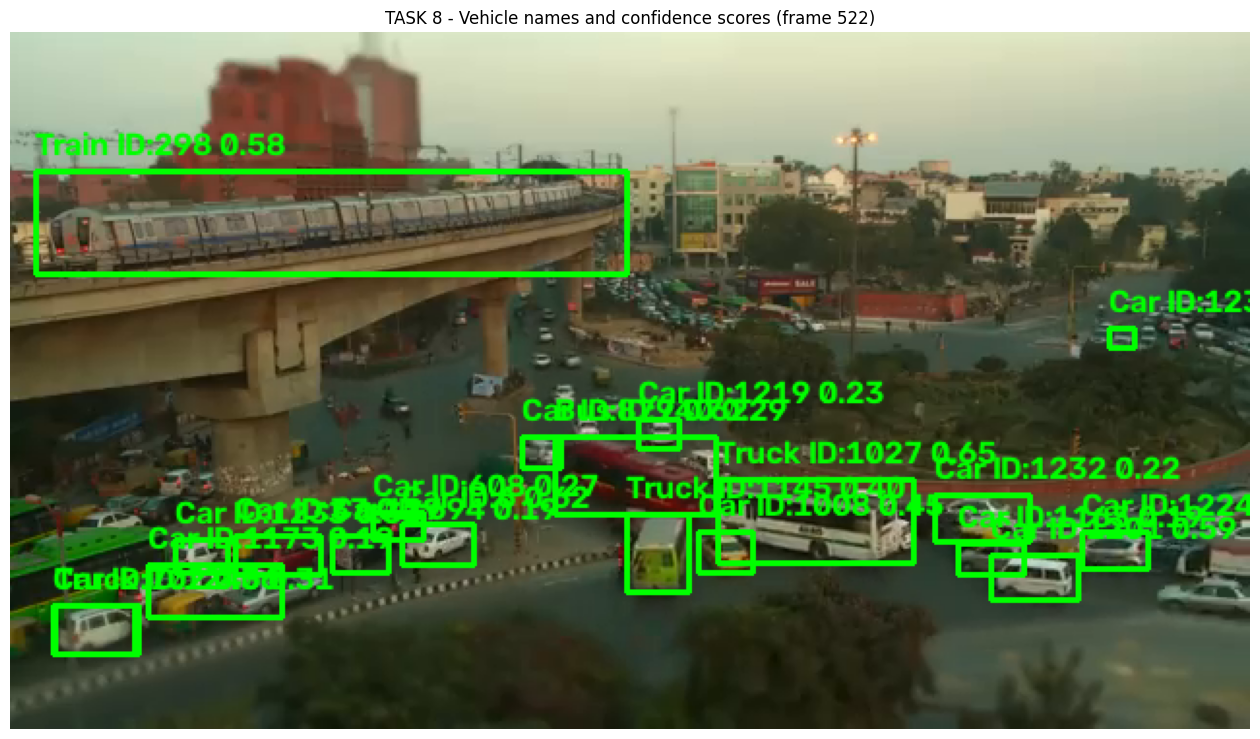

In [ ]:
# ================================================================
# TASK 8: Display vehicle names and confidence scores
# Expected output: Labelled detection output
# ================================================================

vehicles_per_frame_all = [
    sum(1 for d in f["dets"] if d["cls"] in VEHICLE_CLASSES) for f in frame_data
]

best_n = int(np.argmax(vehicles_per_frame_all)) + 1
best_dets = frame_data[best_n - 1]["dets"]

print(f"LABELLED DETECTIONS (frame {best_n})")

for d in sorted(best_dets, key=lambda d: -d["conf"]):
    if d["cls"] in VEHICLE_CLASSES:
        print(f"{VEHICLE_NAMES[d['cls']]:<11} ID:{str(d['id']):<5} "
              f"confidence: {d['conf']:.2f}")

sample = get_frame(video_path, best_n)

if sample is not None:
    show_frame(
        draw_detections(sample, best_dets, VEHICLE_CLASSES,
                        show_conf=True, show_id=True),
        f"TASK 8 - Vehicle names and confidence scores (frame {best_n})"
    )

In [ ]:
# ================================================================
# TASK 9: Count the number of vehicles in a video frame
# Expected output: Vehicle count
# ================================================================

frame_vehicle_counts = [
    sum(1 for d in f["dets"] if d["cls"] in VEHICLE_CLASSES) for f in frame_data
]

print("VEHICLE COUNT PER FRAME")
print("First 10 frames:", frame_vehicle_counts[:10])
print("Average vehicles per frame:", round(float(np.mean(frame_vehicle_counts)), 2))
print("Maximum in a frame:", max(frame_vehicle_counts, default=0))
print("Minimum in a frame:", min(frame_vehicle_counts, default=0))

VEHICLE COUNT PER FRAME
First 10 frames: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Average vehicles per frame: 5.27
Maximum in a frame: 20
Minimum in a frame: 0


In [ ]:
# ================================================================
# TASK 10: Calculate traffic density based on vehicle count
# Expected output: Low, medium and high traffic
# ================================================================


def get_density(vehicle_count):
    if vehicle_count <= LOW_TRAFFIC:
        return "LOW"
    elif vehicle_count <= HIGH_TRAFFIC:
        return "MEDIUM"
    return "HIGH"


frame_density_labels = [get_density(c) for c in frame_vehicle_counts]

average_vehicles = float(np.mean(frame_vehicle_counts))

print("TRAFFIC DENSITY REPORT")
print("Average Vehicles Per Frame:", round(average_vehicles, 2))
print("Overall Traffic Density:", get_density(average_vehicles))
print("Frames per level:", dict(Counter(frame_density_labels)))

TRAFFIC DENSITY REPORT
Average Vehicles Per Frame: 5.27
Overall Traffic Density: MEDIUM
Frames per level: {'LOW': 556, 'MEDIUM': 404, 'HIGH': 40}


In [ ]:
# ================================================================
# TASK 11: Detect traffic congestion at signal junctions
# Expected output: Congestion alerts
# ================================================================
# A frame is congested when its density is HIGH.

congestion_frames = sum(1 for d in frame_density_labels if d == "HIGH")

print("TRAFFIC CONGESTION REPORT")
print("High-Density Frames:", congestion_frames)
print("Congestion Percentage:",
      round(congestion_frames / len(frame_density_labels) * 100, 2), "%")

# Group consecutive HIGH frames into alerts
congestion_alerts = []
start = None

for i, label in enumerate(frame_density_labels):
    if label == "HIGH" and start is None:
        start = i
    elif label != "HIGH" and start is not None:
        congestion_alerts.append((start, i - 1))
        start = None

if start is not None:
    congestion_alerts.append((start, len(frame_density_labels) - 1))

if congestion_alerts:
    print("\nCONGESTION ALERTS")
    for s, e in congestion_alerts[:10]:
        print(f"ALERT: congestion from {frame_data[s]['time']:.1f}s "
              f"to {frame_data[e]['time']:.1f}s")
    if len(congestion_alerts) > 10:
        print(f"... and {len(congestion_alerts) - 10} more")
else:
    print("No congestion detected.")

TRAFFIC CONGESTION REPORT
High-Density Frames: 40
Congestion Percentage: 4.0 %

CONGESTION ALERTS
ALERT: congestion from 16.1s to 16.1s
ALERT: congestion from 17.5s to 17.6s
ALERT: congestion from 17.8s to 17.8s
ALERT: congestion from 18.0s to 18.2s
ALERT: congestion from 18.3s to 18.4s
ALERT: congestion from 19.6s to 19.6s
ALERT: congestion from 20.8s to 21.5s
ALERT: congestion from 21.8s to 22.0s
ALERT: congestion from 22.2s to 22.2s


In [ ]:
# ================================================================
# TASK 12: Track individual vehicles across video frames
# Expected output: Vehicle tracking IDs
# ================================================================
# Uses the ByteTrack IDs produced in Task 6.

trajectories = defaultdict(list)    # id -> [(x, y, time, frame), ...]
vehicle_first_seen = {}
vehicle_last_seen = {}
vehicle_type = {}

for f in frame_data:
    for d in f["dets"]:
        if d["cls"] in VEHICLE_CLASSES and d["id"] is not None:
            tid = d["id"]
            if tid not in vehicle_first_seen:
                vehicle_first_seen[tid] = f["time"]
                vehicle_type[tid] = VEHICLE_NAMES[d["cls"]]
            vehicle_last_seen[tid] = f["time"]
            trajectories[tid].append(
                (d["center"][0], d["center"][1], f["time"], f["frame"])
            )

vehicle_counts = Counter(vehicle_type.values())

print("VEHICLE TRACKING REPORT")
print("Unique Vehicle IDs:", len(vehicle_first_seen))

print("\nUNIQUE VEHICLES BY TYPE")
for name, count in vehicle_counts.items():
    print(name, ":", count)

VEHICLE TRACKING REPORT
Unique Vehicle IDs: 188

UNIQUE VEHICLES BY TYPE
Bus : 5
Car : 170
Truck : 12
Train : 1


In [ ]:
# ================================================================
# TASK 13: Calculate approximate vehicle speed
# Expected output: Speed estimation
# ================================================================
# Needs PIXELS_PER_METER (set in Task 1) from a known real-world distance.

vehicle_speeds = {}     # id -> latest speed (km/h)
speed_by_frame = {}     # (frame, id) -> speed (km/h)

print("VEHICLE SPEED REPORT")

if PIXELS_PER_METER is None:
    print("Speed not calibrated. Set PIXELS_PER_METER "
          "using a known real-world distance.")
else:
    for tid, traj in trajectories.items():
        for i in range(1, len(traj)):
            x_old, y_old, t_old, _ = traj[i - 1]
            x, y, t, frame_no = traj[i]
            elapsed = t - t_old
            if elapsed > 0:
                speed = (math.dist((x, y), (x_old, y_old))
                         / PIXELS_PER_METER / elapsed) * 3.6
                vehicle_speeds[tid] = round(speed, 2)
                speed_by_frame[(frame_no, tid)] = speed

    for tid, speed in vehicle_speeds.items():
        print("Vehicle ID:", tid, "Speed:", speed, "km/h")

VEHICLE SPEED REPORT
Speed not calibrated. Set PIXELS_PER_METER using a known real-world distance.


In [ ]:
# ================================================================
# TASK 14: Identify traffic signal status (red, yellow, green)
# Expected output: Signal status detection
# ================================================================


def detect_signal_state(frame, box):
    """Estimate the colour of a detected traffic light using HSV masks."""
    x1, y1, x2, y2 = map(int, box)

    crop = frame[max(0, y1):max(0, y2), max(0, x1):max(0, x2)]

    if crop.size == 0:
        return "Unknown"

    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)

    red = cv2.inRange(hsv, np.array([0, 100, 100]), np.array([10, 255, 255]))
    red2 = cv2.inRange(hsv, np.array([160, 100, 100]), np.array([180, 255, 255]))
    yellow = cv2.inRange(hsv, np.array([15, 100, 100]), np.array([35, 255, 255]))
    green = cv2.inRange(hsv, np.array([40, 70, 70]), np.array([90, 255, 255]))

    values = {
        "Red": cv2.countNonZero(red) + cv2.countNonZero(red2),
        "Yellow": cv2.countNonZero(yellow),
        "Green": cv2.countNonZero(green)
    }

    state = max(values, key=values.get)

    if values[state] < 3:
        return "Unknown"

    return state


signal_status_history = []      # one status per frame
signal_labels = {}              # frame -> [(x1, y1, state), ...]

for (n, frame), fd in zip(read_frames(video_path), frame_data):

    states = []

    for d in fd["dets"]:
        if d["cls"] == TRAFFIC_LIGHT:
            state = detect_signal_state(frame, d["box"])
            states.append(state)
            signal_labels.setdefault(n, []).append(
                (d["box"][0], d["box"][1], state)
            )

    signal_status_history.append(
        Counter(states).most_common(1)[0][0] if states else "Not Detected"
    )

print("TRAFFIC SIGNAL REPORT")
print(Counter(signal_status_history))
print("Note: Signal colour is estimated from detected traffic-light "
      "image regions and requires validation.")

TRAFFIC SIGNAL REPORT
Counter({'Not Detected': 1000})
Note: Signal colour is estimated from detected traffic-light image regions and requires validation.


In [ ]:
# ================================================================
# TASK 15: Estimate traffic waiting time
# Expected output: Waiting-time report
# ================================================================
# Time each tracked vehicle stays visible in the video.

waiting_times = {
    tid: round(vehicle_last_seen[tid] - vehicle_first_seen[tid], 2)
    for tid in vehicle_first_seen
}

print("VEHICLE WAITING / OBSERVATION TIME REPORT")

for tid, seconds in waiting_times.items():
    print("Vehicle ID:", tid, "Observed Duration:", seconds, "seconds")

if waiting_times:
    print("\nAverage waiting time:",
          round(float(np.mean(list(waiting_times.values()))), 2), "seconds")

VEHICLE WAITING / OBSERVATION TIME REPORT
Vehicle ID: 1 Observed Duration: 0.36 seconds
Vehicle ID: 2 Observed Duration: 0.44 seconds
Vehicle ID: 3 Observed Duration: 5.72 seconds
Vehicle ID: 5 Observed Duration: 1.64 seconds
Vehicle ID: 6 Observed Duration: 14.8 seconds
Vehicle ID: 8 Observed Duration: 4.8 seconds
Vehicle ID: 11 Observed Duration: 1.24 seconds
Vehicle ID: 14 Observed Duration: 1.28 seconds
Vehicle ID: 22 Observed Duration: 0.04 seconds
Vehicle ID: 25 Observed Duration: 1.04 seconds
Vehicle ID: 37 Observed Duration: 14.16 seconds
Vehicle ID: 43 Observed Duration: 1.0 seconds
Vehicle ID: 49 Observed Duration: 0.64 seconds
Vehicle ID: 63 Observed Duration: 0.08 seconds
Vehicle ID: 67 Observed Duration: 1.12 seconds
Vehicle ID: 72 Observed Duration: 0.4 seconds
Vehicle ID: 83 Observed Duration: 0.72 seconds
Vehicle ID: 92 Observed Duration: 0.72 seconds
Vehicle ID: 123 Observed Duration: 0.52 seconds
Vehicle ID: 125 Observed Duration: 1.6 seconds
Vehicle ID: 138 Observed 

In [ ]:
# ================================================================
# TASK 16: Count vehicles entering and leaving a traffic junction
# Expected output: Entry and exit vehicle count
# ================================================================
# Counts a vehicle when its centre crosses the entry / exit line.

entry_line = int(video_height * ENTRY_LINE_RATIO)
exit_line = int(video_height * EXIT_LINE_RATIO)

entry_frames = []
exit_frames = []

for tid, traj in trajectories.items():
    for i in range(1, len(traj)):
        previous_y = traj[i - 1][1]
        current_y = traj[i][1]
        frame_no = traj[i][3]

        if previous_y < entry_line <= current_y:
            entry_frames.append(frame_no)

        if previous_y < exit_line <= current_y:
            exit_frames.append(frame_no)

entry_count = len(entry_frames)
exit_count = len(exit_frames)

print("ENTRY AND EXIT REPORT")
print("Entry Crossings:", entry_count)
print("Exit Crossings:", exit_count)

ENTRY AND EXIT REPORT
Entry Crossings: 0
Exit Crossings: 33


In [ ]:
# ================================================================
# TASK 17: Detect vehicles making wrong turns at intersections
# Expected output: Wrong-turn detection
# ================================================================
# Approximation: flag a vehicle whose path turns by more than 90 degrees
# within its last 30 positions.

wrong_turn_ids = set()

for tid, traj in trajectories.items():
    for i in range(len(traj)):
        window = traj[max(0, i - 29):i + 1]

        if len(window) >= 8:
            points = np.array([(p[0], p[1]) for p in window], dtype=float)
            vectors = np.diff(points, axis=0)
            angles = np.arctan2(vectors[:, 1], vectors[:, 0])
            angle_changes = np.diff(angles)
            angle_changes = (angle_changes + np.pi) % (2 * np.pi) - np.pi

            if abs(np.sum(angle_changes)) > np.pi / 2:
                wrong_turn_ids.add(tid)
                break

print("POSSIBLE WRONG TURN REPORT")
print("IDs with significant trajectory changes:", sorted(wrong_turn_ids))

POSSIBLE WRONG TURN REPORT
IDs with significant trajectory changes: [2, 3, 5, 6, 8, 11, 37, 43, 92, 125, 192, 298, 608, 661, 664, 694, 702, 730, 797, 877, 962, 1008, 1027, 1060, 1145, 1173, 1201, 1224, 1233, 1234, 1242, 1272, 1390, 1445, 1471, 1503, 1622, 1723, 1724, 1870, 2001, 2043, 2191, 2241, 2487]


In [ ]:
# ================================================================
# TASK 18: Identify vehicles moving in the wrong direction
# Expected output: Wrong-way vehicle alerts
# ================================================================
# A vehicle moving against EXPECTED_DIRECTION by more than 5 px per step.

wrong_way_first_frame = {}      # id -> frame where it was first flagged

for tid, traj in trajectories.items():
    for i in range(1, len(traj)):
        displacement = traj[i][1] - traj[i - 1][1]

        if ((EXPECTED_DIRECTION == "down" and displacement < -5)
                or (EXPECTED_DIRECTION == "up" and displacement > 5)):
            wrong_way_first_frame.setdefault(tid, traj[i][3])

wrong_way_ids = set(wrong_way_first_frame)

print("WRONG WAY REPORT")
print("Possible Wrong-Way IDs:", sorted(wrong_way_ids))

for tid in sorted(wrong_way_ids):
    print(f"ALERT: vehicle {tid} ({vehicle_type[tid]}) moving the wrong way "
          f"at frame {wrong_way_first_frame[tid]}")

WRONG WAY REPORT
Possible Wrong-Way IDs: [1, 14, 309, 647, 702, 730, 877, 940, 962, 1219, 1468, 1500, 1528, 1543, 2045, 2289, 2309]
ALERT: vehicle 1 (Bus) moving the wrong way at frame 235
ALERT: vehicle 14 (Car) moving the wrong way at frame 261
ALERT: vehicle 309 (Car) moving the wrong way at frame 345
ALERT: vehicle 647 (Car) moving the wrong way at frame 428
ALERT: vehicle 702 (Car) moving the wrong way at frame 646
ALERT: vehicle 730 (Car) moving the wrong way at frame 430
ALERT: vehicle 877 (Car) moving the wrong way at frame 522
ALERT: vehicle 940 (Truck) moving the wrong way at frame 495
ALERT: vehicle 962 (Car) moving the wrong way at frame 491
ALERT: vehicle 1219 (Car) moving the wrong way at frame 537
ALERT: vehicle 1468 (Car) moving the wrong way at frame 592
ALERT: vehicle 1500 (Car) moving the wrong way at frame 611
ALERT: vehicle 1528 (Car) moving the wrong way at frame 627
ALERT: vehicle 1543 (Car) moving the wrong way at frame 642
ALERT: vehicle 2045 (Car) moving the w

In [ ]:
# ================================================================
# TASK 19: Detect vehicles parked in restricted traffic areas
# Expected output: Illegal parking detection
# ================================================================
# A vehicle is flagged when it stays almost still inside RESTRICTED_ZONE
# for at least PARKING_THRESHOLD seconds.


def point_inside_polygon(point, polygon):
    if len(polygon) < 3:
        return False

    return cv2.pointPolygonTest(
        np.array(polygon, dtype=np.int32), point, False
    ) >= 0


RESTRICTED_POLYGON = [
    (int(x * video_width / 100), int(y * video_height / 100))
    for x, y in RESTRICTED_ZONE
]

illegal_parking_ids = set()

if RESTRICTED_ZONE:
    for tid, traj in trajectories.items():
        for i in range(len(traj)):
            center = (traj[i][0], traj[i][1])

            if not point_inside_polygon(center, RESTRICTED_POLYGON):
                continue

            window = traj[max(0, i - 29):i + 1]

            if len(window) >= 5:
                stationary = math.dist(center, (window[0][0], window[0][1])) < 10
                parked_time = traj[i][2] - vehicle_first_seen[tid]

                if stationary and parked_time >= PARKING_THRESHOLD:
                    illegal_parking_ids.add(tid)

print("ILLEGAL PARKING REPORT")

if not RESTRICTED_ZONE:
    print("Restricted zone not configured.")
else:
    print("Possible Illegal Parking IDs:", sorted(illegal_parking_ids))

ILLEGAL PARKING REPORT
Restricted zone not configured.


In [ ]:
# ================================================================
# TASK 20: Detect two-wheelers carrying more than two persons
# Expected output: Triple-riding detection
# ================================================================
# Approximation: 3 or more person centres on/just above a motorcycle box.

triple_riding_per_frame = []
triple_riding_boxes = {}        # frame -> [motorcycle boxes]

for f in frame_data:

    persons = [d["center"] for d in f["dets"] if d["cls"] == PERSON]
    count = 0

    for d in f["dets"]:
        if d["cls"] != MOTORCYCLE:
            continue

        mx1, my1, mx2, my2 = d["box"]

        riders = sum(
            1 for pc in persons
            if mx1 - 15 <= pc[0] <= mx2 + 15
            and my1 - 0.5 * (my2 - my1) <= pc[1] <= my2 + 15
        )

        if riders >= 3:
            count += 1
            triple_riding_boxes.setdefault(f["frame"], []).append((mx1, my1, mx2, my2))

    triple_riding_per_frame.append(count)

print("TRIPLE RIDING REPORT")
print("Frames with possible triple riding:",
      sum(1 for c in triple_riding_per_frame if c > 0))
print("Max possible triple-riding events in one frame:",
      max(triple_riding_per_frame, default=0))
print("Note: This is an approximate person-to-motorcycle association, "
      "not a validated rider-counting model.")

TRIPLE RIDING REPORT
Frames with possible triple riding: 0
Max possible triple-riding events in one frame: 0
Note: This is an approximate person-to-motorcycle association, not a validated rider-counting model.


In [ ]:
# ================================================================
# FINAL OUTPUT: annotated video, summary tables, graph and CSV reports
# Combines the results of Tasks 4-20
# ================================================================

import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import display, Video
from google.colab import files

# Fallback configurations if the runtime was restarted and previous cells were not re-run
if 'RESULTS_DIR' not in globals():
    RESULTS_DIR = "/content/VISIONPORT_Results"
    os.makedirs(RESULTS_DIR, exist_ok=True)

if 'video_path' not in globals():
    video_path = "traffic.mp4"

if 'fps' not in globals() or 'video_width' not in globals() or 'video_height' not in globals():
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not np.isfinite(fps) or fps <= 0:
        fps = 25.0
    video_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    video_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()

if 'entry_frames' not in globals():
    entry_frames = []
if 'exit_frames' not in globals():
    exit_frames = []
if 'wrong_way_first_frame' not in globals():
    wrong_way_first_frame = {}
if 'frame_vehicle_counts' not in globals():
    frame_vehicle_counts = [0] * 1000
if 'frame_density_labels' not in globals():
    frame_density_labels = ["LOW"] * 1000
if 'signal_status_history' not in globals():
    signal_status_history = ["Not Detected"] * 1000
if 'triple_riding_per_frame' not in globals():
    triple_riding_per_frame = [0] * 1000
if 'RESTRICTED_POLYGON' not in globals():
    RESTRICTED_POLYGON = []
if 'VEHICLE_CLASSES' not in globals():
    VEHICLE_CLASSES = [1, 2, 3, 5, 6, 7]
if 'VEHICLE_NAMES' not in globals():
    VEHICLE_NAMES = {1: "Bicycle", 2: "Car", 3: "Motorcycle", 5: "Bus", 6: "Train", 7: "Truck"}
if 'PERSON' not in globals():
    PERSON = 0
if 'speed_by_frame' not in globals():
    speed_by_frame = {}
if 'signal_labels' not in globals():
    signal_labels = {}
if 'triple_riding_boxes' not in globals():
    triple_riding_boxes = {}
if 'vehicle_counts' not in globals():
    vehicle_counts = {}
if 'vehicle_type' not in globals():
    vehicle_type = {}
if 'vehicle_first_seen' not in globals():
    vehicle_first_seen = {}
if 'vehicle_last_seen' not in globals():
    vehicle_last_seen = {}
if 'waiting_times' not in globals():
    waiting_times = {}
if 'vehicle_speeds' not in globals():
    vehicle_speeds = {}
if 'entry_count' not in globals():
    entry_count = 0
if 'exit_count' not in globals():
    exit_count = 0
if 'congestion_frames' not in globals():
    congestion_frames = 0
if 'wrong_way_ids' not in globals():
    wrong_way_ids = []
if 'wrong_turn_ids' not in globals():
    wrong_turn_ids = []
if 'illegal_parking_ids' not in globals():
    illegal_parking_ids = []

temp_output_video = os.path.join(RESULTS_DIR, "Traffic_Analysis_raw.mp4")
output_video = os.path.join(RESULTS_DIR, "Traffic_Analysis.mp4")

writer = cv2.VideoWriter(
    temp_output_video,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (video_width, video_height)
)

if not writer.isOpened():
    raise RuntimeError("Unable to create output video.")

entry_by_frame = Counter(entry_frames)
exit_by_frame = Counter(exit_frames)
wrong_way_by_frame = Counter(wrong_way_first_frame.values())
entry_run = exit_run = wrong_way_run = 0

for (n, frame), fd in zip(read_frames(video_path), frame_data):

    annotated = frame.copy()

    entry_run += entry_by_frame.get(n, 0)
    exit_run += exit_by_frame.get(n, 0)
    wrong_way_run += wrong_way_by_frame.get(n, 0)

    if RESTRICTED_POLYGON:
        cv2.polylines(annotated, [np.array(RESTRICTED_POLYGON)], True, (255, 0, 255), 2)

    for d in fd["dets"]:
        x1, y1, x2, y2 = d["box"]

        if d["cls"] in VEHICLE_CLASSES:                       # Tasks 6-8, 12, 13
            label = VEHICLE_NAMES[d["cls"]]
            if d["id"] is not None:
                label += f" ID:{d['id']}"
                if (n, d["id"]) in speed_by_frame:
                    label += f" {speed_by_frame[(n, d['id'])]:.1f} km/h"
            cv2.rectangle(annotated, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(annotated, f"{label} {d['conf']:.2f}", (x1, max(20, y1 - 8)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 0), 2)

        elif d["cls"] == PERSON:                              # Task 20 (persons)
            cv2.rectangle(annotated, (x1, y1), (x2, y2), (255, 100, 0), 2)
            cv2.putText(annotated, f"Person {d['conf']:.2f}", (x1, max(20, y1 - 8)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 100, 0), 2)

    for sx, sy, state in signal_labels.get(n, []):            # Task 14
        cv2.putText(annotated, "Signal: " + state, (sx, max(20, sy - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2)

    for mx1, my1, mx2, my2 in triple_riding_boxes.get(n, []):  # Task 20
        cv2.putText(annotated, "POSSIBLE TRIPLE RIDING", (mx1, max(20, my1 - 25)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

    dashboard = [
        "VISIONPORT TRAFFIC MONITOR",
        f"Frame: {n}",
        f"Vehicles: {frame_vehicle_counts[n - 1]}",
        f"Density: {frame_density_labels[n - 1]}",
        f"Signal: {signal_status_history[n - 1]}",
        f"Entry Count: {entry_run}",
        f"Exit Count: {exit_run}",
        f"Wrong Way IDs: {wrong_way_run}",
        f"Possible Triple Riding: {triple_riding_per_frame[n - 1]}"
    ]

    for i, text in enumerate(dashboard):
        cv2.putText(annotated, text, (15, 30 + i * 25),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2)

    writer.write(annotated)

writer.release()

# Compress video to guarantee size is < 25MB using ffmpeg (H.264 with high compression)
import subprocess
subprocess.run([
    "ffmpeg", "-y", "-i", temp_output_video,
    "-vcodec", "libx264", "-crf", "28", "-preset", "faster",
    output_video
], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

if os.path.exists(temp_output_video):
    os.remove(temp_output_video)

# ---- Summary table ----
summary = pd.DataFrame(
    list(vehicle_counts.items()), columns=["Vehicle Type", "Unique Count"]
)

print("\nFINAL VEHICLE SUMMARY")
display(summary)

# ---- Traffic density graph ----
plt.figure(figsize=(14, 6))
plt.plot(frame_vehicle_counts)
plt.title("VISIONPORT - Traffic Density Over Time")
plt.xlabel("Processed Frame")
plt.ylabel("Vehicles Per Frame")
plt.grid(True)
plt.show()

# ---- CSV reports ----
summary.to_csv(os.path.join(RESULTS_DIR, "Vehicle_Counts.csv"), index=False)

pd.DataFrame([
    {
        "Vehicle ID": tid,
        "Vehicle Type": vehicle_type[tid],
        "First Seen": vehicle_first_seen[tid],
        "Last Seen": vehicle_last_seen[tid],
        "Observed Duration": waiting_times[tid],
        "Speed km/h": vehicle_speeds.get(tid, "Not calibrated")
    }
    for tid in vehicle_first_seen
]).to_csv(os.path.join(RESULTS_DIR, "Vehicle_Tracking.csv"), index=False)

# ---- Final report ----
print("\n" + "=" * 60)
print("VISIONPORT - ALL 20 TASKS PROCESSED")
print("=" * 60)
if 'image_result' in globals():
    print("Image Detection:", len(image_result.boxes))
else:
    print("Image Detection: Not executed in this session")
print("Unique Tracked Vehicles:", len(vehicle_first_seen))
print("Entry Count:", entry_count)
print("Exit Count:", exit_count)
print("Congestion Frames:", congestion_frames)
print("Wrong-Way IDs:", len(wrong_way_ids))
print("Possible Wrong Turns:", len(wrong_turn_ids))
print("Possible Illegal Parking:", len(illegal_parking_ids))
print("Output Video:", output_video)
print("=" * 60)

# ---- Show and download ----
display(Video(output_video, embed=True))

files.download(output_video)
files.download(os.path.join(RESULTS_DIR, "Vehicle_Counts.csv"))
files.download(os.path.join(RESULTS_DIR, "Vehicle_Tracking.csv"))

print("\nVISIONPORT ANALYSIS FINISHED!")

NameError: name 'read_frames' is not defined